# Superconductors: power laws, AC loss and trapped fields (TPHI2D_edge)

This notebook follows `examples/wire_2D_tphi` and `examples/bulk_2D_tphi_axisym`: the 2D H-formulation (T-phi on 2D
cells, `TPHI2D_edge`) with the E-J power law of superconductors,

$$\mathbf{E}=E_c\left(\frac{|\mathbf{J}|}{J_c}\right)^n\frac{\mathbf{J}}{|\mathbf{J}|}\ (+\rho_0\mathbf{J}),$$

a resistivity $\rho(J)=E(J)/J$ given as a table. It shows:

1. how to write the E-J table (and why it ends with a normal-state segment);
2. the AC transport loss of a round wire (planar 2D, a cut) against Norris's critical-state formula, its current
   fronts, and the convergence to the critical state as n grows;
3. the nonlinear settings that work at REBCO-level n (and the ones that fail);
4. a REBCO bulk (axisymmetric) magnetized by field cooling with a field-dependent $J_c(B)$ (`power_law_b`): the
   trapped field and its creep.

See the user manual (*Element library: TPHI2D_edge*, *Nonlinear laws*: *Superconductors: the nonlinear settings*).
The wire alone runs about 40 s per exponent.

In [1]:
import contextlib, io, os, shutil, tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

import pytec3d
from pytec3d import Solver, selection, tree_gauge
from pytec3d import mesh as meshes

pv.set_jupyter_backend("static")          # images in the notebook; "trame" gives interactive views
pytec3d.set_log_level("ERROR")            # the job log keeps everything (<model>.log in the working folder)
MU0 = 4e-7 * np.pi
QUIET = {"-ksp_monitor": None, "-ksp_view": None, "-ksp_converged_reason": None, "-log_view": None,
         "-ksp_monitor_true_residual": None, "-ksp_monitor_solution": None}   # no PETSc reports in the notebook

import sys
sys.path.insert(0, os.getcwd())               # docs/tutorials: the plotting helpers of the notebooks
from setup_views import view                  # regions, selected nodes and edges of a setup step
EXAMPLES = Path("../../examples").resolve()
WORK = Path(tempfile.mkdtemp(prefix="pytec3d_sc_"))
for case in ("wire_2D_tphi", "bulk_2D_tphi_axisym"):
    folder = EXAMPLES / case
    for f in (case + ".vtu", "model_data.json"):
        shutil.copy(folder / f, WORK / f"{case}_{f}" if f == "model_data.json" else WORK / f)
os.chdir(WORK)
print("working in a temporary folder:", WORK.name)

def quietly():
    """Keep the report tables of the solver (and libMesh's Newton trace) out of the notebook: they are in the job log."""
    return contextlib.redirect_stdout(io.StringIO())

def new_solver(case, log):
    """A solver on the example's mesh and model data (model_data.json copied as <case>_model_data.json)."""
    solver = Solver(log_file=log)
    solver.read_model(case + ".vtu")
    solver.model.read_json(case + "_model_data.json")
    solver.solver_settings = {"petsc_options": QUIET}
    return solver

def select_surface(grid, conductor, others, midside):
    """Select the points shared by the cells of TYPE ``conductor`` and those of TYPEs ``others`` (the surface of the
    conductor): its midside points (midside=True: the edge DOFs) or its corner points."""
    selection.select(grid, "TYPE", conductor, location="elem"); selection.nsle(grid)
    selection.select(grid, "TYPE", list(others), location="elem"); selection.nsle(grid, mode="r")
    selection.select(grid, "MidsideNodes", int(midside), mode="r")

def select_inside(grid, conductor, others):
    """Select the corner points of the cells of TYPE ``conductor`` that no cell of TYPEs ``others`` has."""
    selection.select(grid, "TYPE", conductor, location="elem"); selection.nsle(grid)
    selection.select(grid, "TYPE", list(others), location="elem"); selection.nsle(grid, mode="u")
    selection.select(grid, "MidsideNodes", 0, mode="r")

working in a temporary folder: pytec3d_sc_eirz3hby


## The E-J table

`set_power_law(mat, table)` takes rows $[J, E]$ from $J=0$, both increasing; the law `power_law` interpolates it
linearly and **continues along its last segment**. Three rules (measured on the `formulations` benchmarks):

* enough points where the curve bends: log-spaced from $10^{-4}J_c$, 0.6 % apart;
* a negligible floor $\rho_0$ (its diffusion time $\mu_0L^2/\rho_0$ much longer than the run): it is the resistivity
  at $J\to0$ (the first segment);
* **a normal-state end**: above $E_\text{max}=100E_c$ a segment of the normal resistivity (current sharing). A pure
  power law continued by a Newton iterate far above $J_c$ gives tangents of $10^{30}$, and the factorization fails.

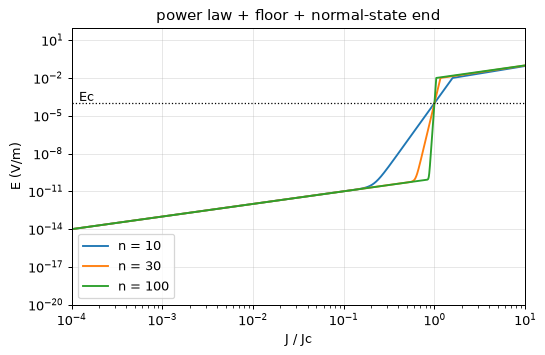

In [2]:
def power_law_table(jc, n, ec=1e-4, rho0=1e-14, e_max=1e-2, rho_n=1e-6):
    j = np.concatenate(([0.0], jc * np.geomspace(1e-4, 10.0, 2001)))
    e = rho0 * j + ec * (j / jc) ** n
    keep = e < e_max
    j_max = jc * (e_max / ec) ** (1.0 / n)
    return np.column_stack((np.concatenate((j[keep], [j_max, 10 * j_max])),
                            np.concatenate((e[keep], [e_max, e_max + rho_n * 9 * j_max]))))

fig, ax = plt.subplots(figsize=(6.5, 4))
for n in (10, 30, 100):
    t = power_law_table(1e4, n)
    ax.loglog(t[1:, 0] / 1e4, t[1:, 1], label=f"n = {n}")
ax.axhline(1e-4, color="k", ls=":", lw=1); ax.text(1.2e-4, 1.5e-4, "Ec")
ax.set_xlim(1e-4, 10); ax.set_ylim(1e-20, 1e2)
ax.set_xlabel("J / Jc"); ax.set_ylabel("E (V/m)"); ax.grid(True, which="major", alpha=0.3); ax.legend()
ax.set_title("power law + floor + normal-state end"); plt.show()

## A round wire with an AC transport current

The wire (radius R = 1, scaled units: $J_c=10^4$ A/m², $I_c=J_c\pi R^2$) carries $I(t)=0.5\,I_c\sin(2\pi t/T)$,
T = 40 s (E about $E_c$). Its net current needs a **cut**: a strip of `CUT_LAYER` cells from the wire to the box along
the ray y = 0+, x > R. `_T` = 0 on the strip's edges along the ray and on its other side; `_T` = $\pm I(t)$ on its
crossing edges (the sign from `tree_gauge.edges`); the box carries the exact potential outside a round wire,
$\phi=-I\theta/2\pi$, with $\theta=2\pi$ on the ray: $\phi$ jumps by I across the strip (T carries the jump there).

`wire(n, settings)` runs 1.25 cycles (80 steps per cycle) and returns the loss per cycle, from the first peak to the
next, $Q=\oint\int\mathbf{E}\cdot\mathbf{J}\,dA\,dt$ (the `E` and `Jt` outputs, J/m), the Newton iterations, and the
current density along the x axis at two instants.

In [3]:
JC, EC, F, PERIOD, PER_CYCLE = 1e4, 1e-4, 0.5, 40.0, 80
IC = JC * np.pi
SETTINGS = {"absolute_residual_tolerance": 1e-9, "relative_residual_tolerance": 1e-30, "max_iterations": 100,
            "require_residual_reduction": True}

def norris(f, ic=IC):
    return MU0 * ic**2 / np.pi * ((1 - f) * np.log(1 - f) + (2 - f) * f / 2)

def wire(n, settings=SETTINGS, steps=PER_CYCLE + PER_CYCLE // 4):
    solver = new_solver("wire_2D_tphi", f"wire_n{n:g}.log")
    solver.solver_settings = {"petsc_options": QUIET, "nonlinear": dict(settings, verbose=False)}
    grid = solver.model.mesh
    xyz = meshes.points(grid)
    types = meshes.array_values(grid, "TYPE", "elem")
    solver.model.set_power_law(2, power_law_table(JC, n))
    select_surface(grid, 2, [1, 3], midside=True)
    selection.set_value_on_selection(grid, "_T", 0.0, 2)           # n x T = 0 on the wire surface
    select_inside(grid, 2, [1, 3])
    selection.set_value_on_selection(grid, "_PHI", 0.0)            # PHI = 0 inside the wire
    on_ray = np.isclose(xyz[:, 1], 0.0) & (xyz[:, 0] > 0.0)
    selection.select(grid, "TYPE", 3, location="elem")
    mids, start, end = tree_gauge.edges(grid, selection.selected_ids(grid, "elem"))
    cross = on_ray[start] != on_ray[end]
    sign = np.where(on_ray[start[cross]], 1.0, -1.0)
    selection.select(grid, "ID", mids[~cross])
    selection.set_value_on_selection(grid, "_T", 0.0, 2)           # the strip edges along the cut
    selection.select_all(grid); selection.nsel_ext(grid)
    box = selection.selected_ids(grid, "node")
    theta = np.mod(np.arctan2(xyz[box, 1], xyz[box, 0]), 2 * np.pi)
    theta[on_ray[box]] = 2 * np.pi
    with quietly():
        solver.load_model_into_solver()
    solver.time_step["theta"] = 1.0
    c, vol = meshes.cell_centroids(grid), meshes.cell_sizes(grid)
    axis = (types == 2) & (c[:, 1] > 0) & (c[:, 1] < 0.07 * np.abs(c[:, 0]) + 0.03)   # the first row above y = 0
    order = np.argsort(c[axis, 0])
    dt = PERIOD / PER_CYCLE
    out = {"loss": [], "newton": [], "profiles": {}}
    try:
        for step in range(1, steps + 1):
            t = step * dt
            i = F * IC * np.sin(2 * np.pi * t / PERIOD)
            selection.select(grid, "ID", mids[cross])
            selection.set_value_on_selection(grid, "_T", sign * i, 2)
            selection.select(grid, "ID", box)
            selection.set_value_on_selection(grid, "_PHI", -i * theta / (2 * np.pi))
            solver.time_step["time"] = t
            with quietly():
                solver.solve()
            e, j = meshes.array_values(grid, "E", "elem"), meshes.array_values(grid, "Jt", "elem")
            out["loss"].append(float(np.einsum("ij,ij->i", e, j) @ vol) * dt)
            out["newton"].append(solver.steps[-1]["newton_iterations"])
            if step in (PER_CYCLE // 4, PER_CYCLE // 2):
                out["profiles"][step] = (c[axis, 0][order], j[axis, 2][order] / JC)
    finally:
        with quietly():
            solver.close()
    q = sum(out["loss"][PER_CYCLE // 4:PER_CYCLE // 4 + PER_CYCLE])
    out.update(Q=q, ratio=q / norris(F))
    return out

w30 = wire(30)
print(f"n = 30: Q = {w30['Q']:.3f} J/m per cycle, Norris {norris(F):.3f} J/m, ratio {w30['ratio']:.3f}; "
      f"Newton iterations per step: mean {np.mean(w30['newton']):.1f}, max {max(w30['newton'])}")

n = 30: Q = 13.721 J/m per cycle, Norris 11.222 J/m, ratio 1.223; Newton iterations per step: mean 8.6, max 13


The cut of the wire as ``wire()`` sets it: the strip of ``CUT_LAYER`` cells, the crossing edges with their sign (the
current I from the ray side to the other, in each edge's own orientation), the edges along the strip at zero, and the
potential of the box with its jump across the strip.

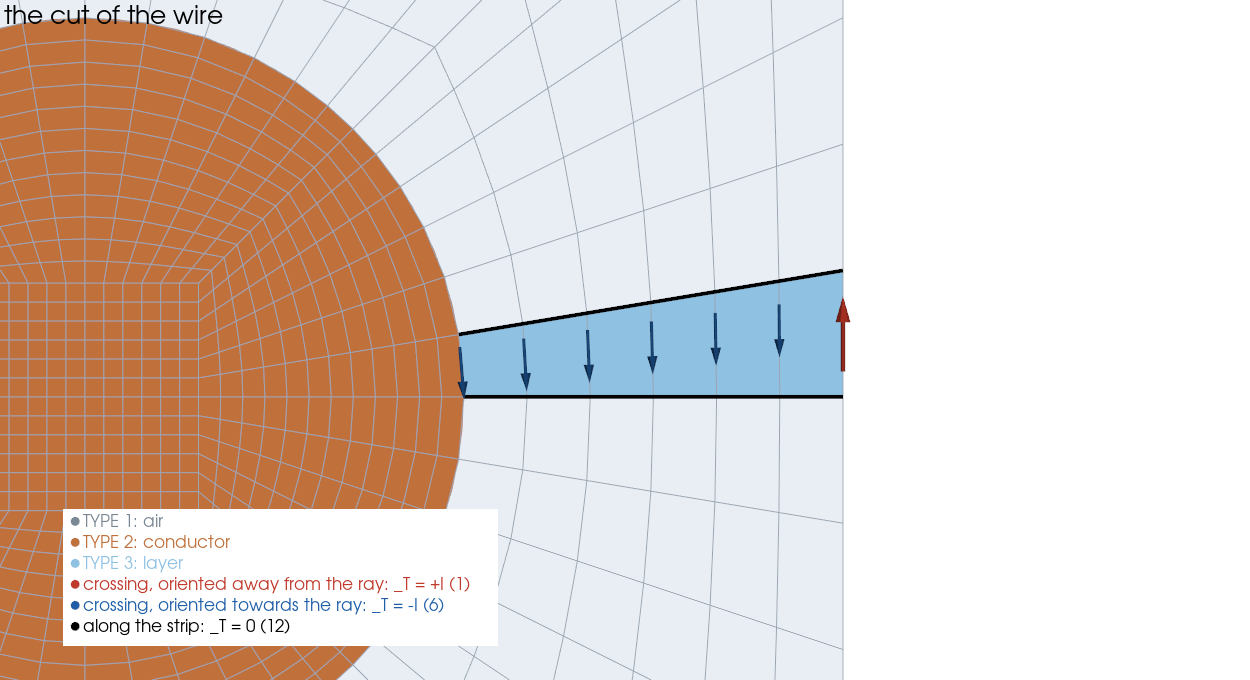

In [4]:
solver = new_solver("wire_2D_tphi", "look.log")
grid = solver.model.mesh
xyz = meshes.points(grid)
on_ray = np.isclose(xyz[:, 1], 0.0) & (xyz[:, 0] > 0.0)
selection.select(grid, "TYPE", 3, location="elem")
mids, start, end = tree_gauge.edges(grid, selection.selected_ids(grid, "elem"))
cross = on_ray[start] != on_ray[end]
plus = cross & on_ray[start]
minus = cross & ~on_ray[start]
(view(grid, regions={1: "air", 2: "conductor", 3: "layer"})
 .edges(start[plus], end[plus], "#c0392b", "crossing, oriented away from the ray: _T = +I", arrows=True)
 .edges(start[minus], end[minus], "#1f5fa8", "crossing, oriented towards the ray: _T = -I", arrows=True)
 .edges(start[~cross], end[~cross], "black", "along the strip: _T = 0", width=4)
 .show("the cut of the wire", bounds=(0.8, 2.05, -0.45, 0.75, 0, 0)))
with quietly():
    solver.close()

The current fronts: at the first peak (t = T/4) the current flows in a shell at the surface, $J\approx J_c$ for
$R\sqrt{1-F}<r<R$ in the critical state (dotted); at the zero crossing (t = T/2) the current of the previous half
cycle stays in the inner part of the shell and a reversed layer has entered from the surface.

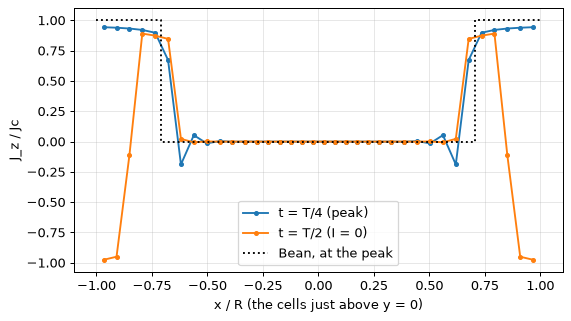

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for step, label in ((PER_CYCLE // 4, "t = T/4 (peak)"), (PER_CYCLE // 2, "t = T/2 (I = 0)")):
    x, j = w30["profiles"][step]
    ax.plot(x, j, "o-", ms=3, label=label)
r_front = np.sqrt(1 - F)
ax.plot([-1, -r_front, -r_front, r_front, r_front, 1], [1, 1, 0, 0, 1, 1], "k:", label="Bean, at the peak")
ax.set_xlabel("x / R (the cells just above y = 0)"); ax.set_ylabel("J_z / Jc"); ax.grid(alpha=0.3); ax.legend(); plt.show()

## The exponent: from a resistor to the critical state

The power law tends to Bean's critical state as n grows. The ratio of the loss to Norris's formula goes from well
above 1 at low n towards 1; at n = 30-100 (REBCO, Nb-Ti) it is 1.2-1.1: compare with the critical state at the n of
the material, not with $n\to\infty$. The Newton iterations grow with n.

In [6]:
sweep = {30: w30}
for n in (10, 100):
    sweep[n] = wire(n)
print(" n    Q / Q_Norris   Newton its (mean, max)")
for n in sorted(sweep):
    print(f"{n:3d}   {sweep[n]['ratio']:10.3f}     {np.mean(sweep[n]['newton']):5.1f}, {max(sweep[n]['newton'])}")

 n    Q / Q_Norris   Newton its (mean, max)
 10        1.490       6.1, 8
 30        1.223       8.6, 13
100        1.113      10.3, 17


## Nonlinear settings: what fails, and why

The defaults of `solver_settings["nonlinear"]` (relative residual tolerance $10^{-8}$, 50 iterations, no residual
reduction required) are made for iron. On the wire at n = 30:

In [7]:
for name, settings in (("defaults", {}),
                       ("absolute tolerance, no residual reduction",
                        {"absolute_residual_tolerance": 1e-9, "relative_residual_tolerance": 1e-30, "max_iterations": 100})):
    try:
        wire(30, settings, steps=6)
        print(f"{name}: 6 steps solved")
    except pytec3d.errors.ConvergenceError as error:
        print(f"{name}: {str(error).split('. See')[0]}")

defaults: t = 1.5: the Newton solver did not converge (maximum iterations reached, 50 iteration(s))
absolute tolerance, no residual reduction: t = 1.5: the Newton solver did not converge (maximum iterations reached, 100 iteration(s))


Both stop at the third step: the transport current changes at the few cells next to the cut, the first iterate has
$J\gg J_c$ there, and the full Newton steps run away. The rules (user manual, *Superconductors: the nonlinear
settings*):

* an **absolute** residual tolerance scaled to the problem (a fraction of $E_c$ times a face area per T row; here
  $10^{-9}$), the relative one off ($10^{-30}$): a relative tolerance is relative to the first residual of the step,
  huge when the starting guess has $J>J_c$ (at n = 100 it accepted $E\approx10^{20}E_c$ on the slab benchmark); a loose
  absolute tolerance stops at once on a wrong state; check $\max|E|$ against $E_c$;
* **require the residual to decrease** for a transport current through a cut (as here), **but not** from a
  current-free conductor in a changing field (the bulk below: the first full step overshoots and must be taken);
* Brent and plain backtracking give the same results; Picard does not converge on the power law.

## A field-cooled REBCO bulk with Jc(B)

The bulk disk (radius 10 mm, thickness 10 mm, axisymmetric half section, `option3` = 1: (x, y) = (r, z), component 2
of `Jt` and `E` azimuthal) is cooled in 2 T, then the field is ramped to zero in 100 s and held. The critical current
depends on the field, the Kim model $J_c(B)=J_{c0}/(1+|B|/B_0)$, $J_{c0}=3\times10^8$ A/m², $B_0$ = 0.5 T, n = 25:
the law `power_law_b`, $E=E_0(J/s(|B|))$, two tables (`set_power_law(mat, table, jc_b=rows)`).

* no cut: the section touches the axis, the air of the half plane is simply connected;
* the **static step** first: the cooled state, B uniform and no current. In a static step the model sets T = 0 on
  every conductor edge and frees $\phi$ inside; the transient steps restore $\mathbf{n}\times\mathbf{T}=0$ on the
  surface and $\phi$ = 0 inside;
* the applied field on the box, $\phi=-H_a(t)z$.

We run the example macro as it is (`examples/bulk_2D_tphi_axisym/macro.py`) and read its output files.

The gauges of the bulk on the two kinds of steps (near the corner r = 10 mm, z = 5 mm):

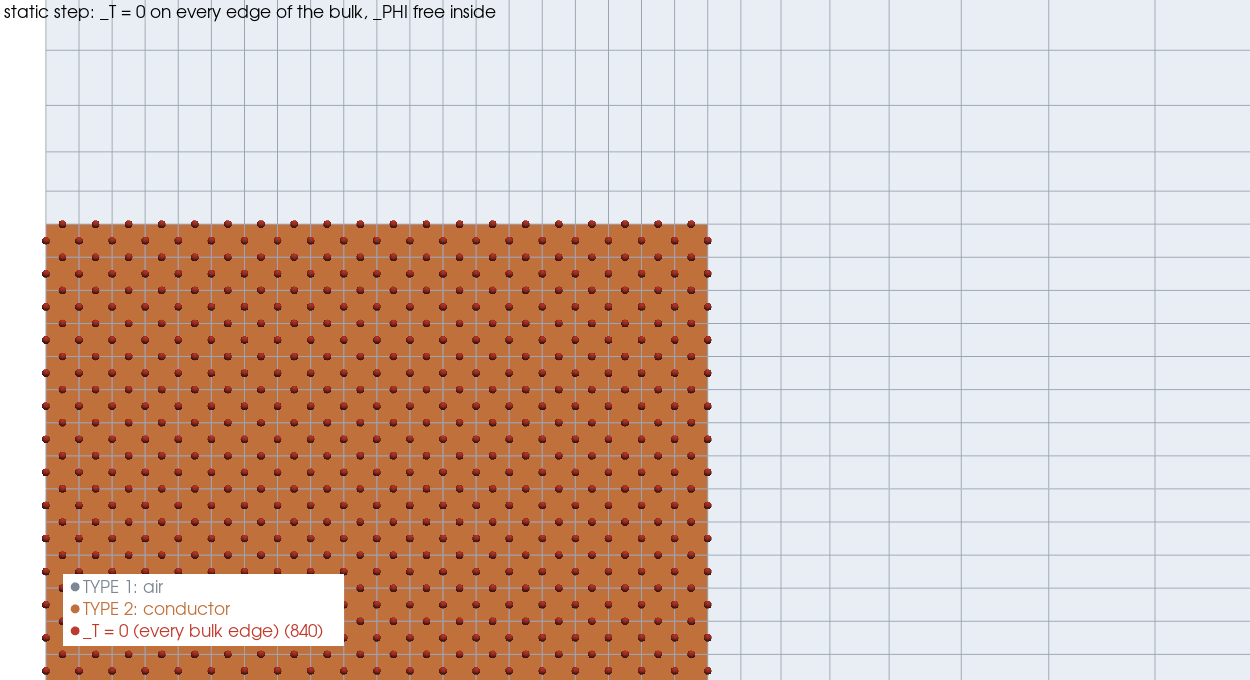

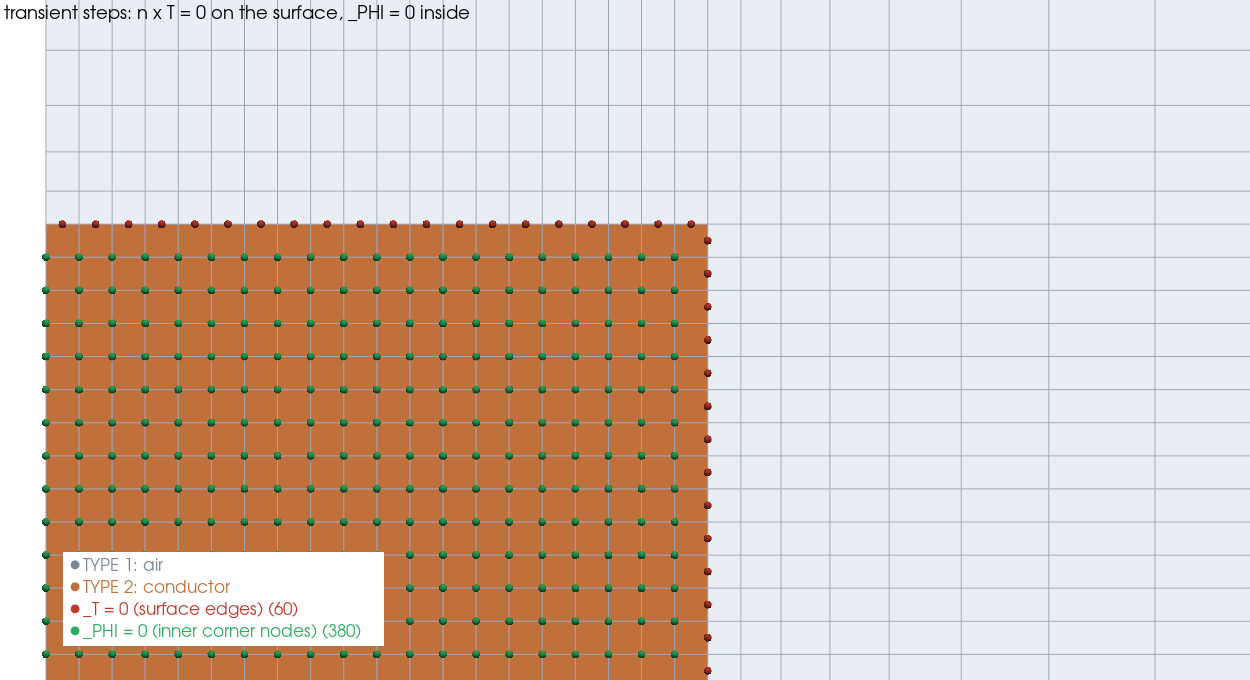

In [8]:
solver = new_solver("bulk_2D_tphi_axisym", "look.log")
grid = solver.model.mesh
selection.select(grid, "TYPE", 2, location="elem"); selection.nsle(grid)
selection.select(grid, "MidsideNodes", 1, mode="r")
all_edges = selection.selected_ids(grid)
selection.select(grid, "TYPE", 1, location="elem"); selection.nsle(grid, mode="r")
surface = selection.selected_ids(grid)
selection.select(grid, "TYPE", 2, location="elem"); selection.nsle(grid)
selection.select(grid, "TYPE", 1, location="elem"); selection.nsle(grid, mode="u")
selection.select(grid, "MidsideNodes", 0, mode="r")
inner = selection.selected_ids(grid)
corner = (0.005, 0.0125, 0.0, 0.0065, 0, 0)
view(grid, regions={1: "air", 2: "conductor"}).nodes(all_edges, "#c0392b", "_T = 0 (every bulk edge)").show(
    "static step: _T = 0 on every edge of the bulk, _PHI free inside", bounds=corner)
(view(grid, regions={1: "air", 2: "conductor"}).nodes(surface, "#c0392b", "_T = 0 (surface edges)")
 .nodes(inner, "#27ae60", "_PHI = 0 (inner corner nodes)")
 .show("transient steps: n x T = 0 on the surface, _PHI = 0 inside", bounds=corner))
with quietly():
    solver.close()

In [9]:
import csv, runpy
shutil.copy("bulk_2D_tphi_axisym_model_data.json", "model_data.json")    # the macro reads model_data.json
with quietly(), contextlib.redirect_stderr(io.StringIO()):
    namespace = runpy.run_path(str(EXAMPLES / "bulk_2D_tphi_axisym" / "macro.py"), run_name="__main__")
    namespace["pytec3d"].close()                                         # writes the steps file
steps = list(csv.DictReader(open("output/bulk_2D_tphi_axisym_steps.csv")))
print(len(steps), "steps; columns of the steps file:", ", ".join(steps[0]))
print("Newton iterations per step:", " ".join(s["newton_iterations"] for s in steps))

63 steps; columns of the steps file: index, time, nonlinear, newton_iterations, linear_iterations, convergence, true_residual, max_law_input, wall_seconds, output
Newton iterations per step: 1 18 16 17 15 15 15 16 14 14 15 15 15 14 16 14 6 6 6 6 6 6 6 6 6 6 6 6 6 7 7 7 7 7 7 7 7 8 8 8 8 8 8 8 8 9 9 9 9 9 9 6 6 5 5 5 4 4 4 4 4 3 3


The steps file (`output/<model>_steps.csv`) lists each step with its time, Newton iterations, convergence and output
file; from the output files we read B at the probe (1 mm above the centre of the top face) and the current density.

trapped field at the probe: 0.546 T at the end of the ramp, 0.479 T at t = 262 s


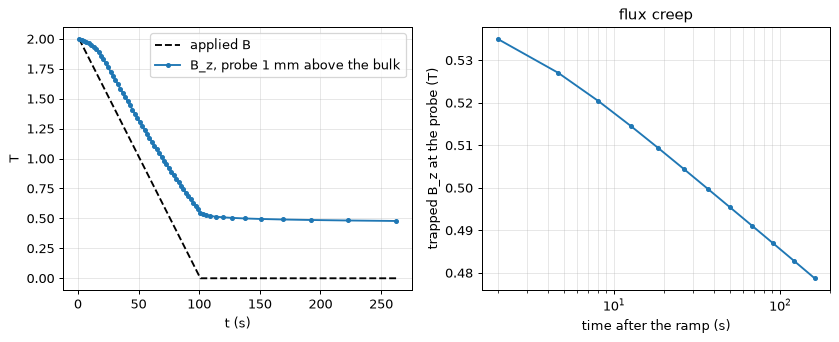

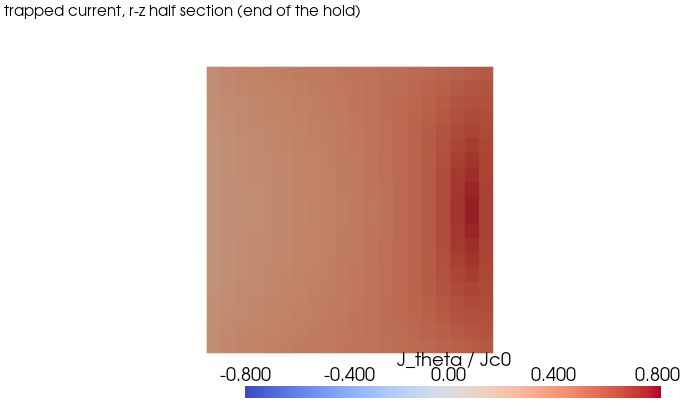

In [10]:
probe_xyz = np.array([0.0, 6e-3, 0.0])
t, b_probe = [], []
for s in steps:
    g = pv.wrap(meshes.read_mesh(s["output"]))
    k = int(np.argmin(np.linalg.norm(g.points - probe_xyz, axis=1)))
    t.append(float(s["time"])); b_probe.append(g.point_data["B"][k, 1])
t, b_probe = np.array(t), np.array(b_probe)
print(f"trapped field at the probe: {b_probe[np.argmin(np.abs(t - 101.0))]:.3f} T at the end of the ramp, "
      f"{b_probe[-1]:.3f} T at t = {t[-1]:.0f} s")

ba = 2.0 * np.clip(1 - (t - 1.0) / 100.0, 0, 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(t, ba, "k--", label="applied B")
ax[0].plot(t, b_probe, "o-", ms=3, label="B_z, probe 1 mm above the bulk")
ax[0].set_xlabel("t (s)"); ax[0].set_ylabel("T"); ax[0].legend(); ax[0].grid(alpha=0.3)
hold = t > 101.5
ax[1].semilogx(t[hold] - 101.0, b_probe[hold], "o-", ms=3)
ax[1].set_xlabel("time after the ramp (s)"); ax[1].set_ylabel("trapped B_z at the probe (T)")
ax[1].set_title("flux creep"); ax[1].grid(True, which="both", alpha=0.3)
plt.show()

g = pv.wrap(meshes.read_mesh(steps[-1]["output"]))
bulk = g.threshold((2, 2), scalars="TYPE")
bulk.cell_data["J_theta / Jc0"] = bulk.cell_data["Jt"][:, 2] / 3e8
p = pv.Plotter(window_size=(700, 420))
p.add_mesh(bulk, scalars="J_theta / Jc0", cmap="coolwarm", clim=(-0.8, 0.8))
p.view_xy(); p.add_text("trapped current, r-z half section (end of the hold)", font_size=10); p.show()

The bulk traps about 0.5 T at the probe; during the hold the currents relax (with a power law E > 0 wherever
$J\approx J_c$) and the trapped field decays roughly linearly in log t, as measured on real bulks. The current fills
the whole section, lowest where |B| is largest (the Kim model: the centre of the disk).

## Takeaways

* `TPHI2D_edge`: planar (per `thickness`) or axisymmetric (`option3` = 1); J and E out of the plane (component 2).
* Power laws as tables with a floor and a normal-state end; `power_law_b` for $J_c(B)$ (the Jacobian has no
  $\partial/\partial B$ term: more iterations, the same solution).
* High n needs an absolute residual tolerance; `require_residual_reduction` for transport currents through cuts, not
  for current-free starts in a changing field.
* A static step gives an initial magnetostatic state (field cooling); the transient steps restore the gauges.
* The power-law loss approaches the critical state as n grows (1.2 at n = 30, 1.1 at n = 100).